# Generative AI for Data Analysis: Practical Business Use Cases & Applications

## Contents

1. [GenAI in the data analysis lifecycle](#1-genai-in-the-data-analysis-lifecycle)
2. [Data cleaning with Generative AI](#2-data-cleaning-with-generative-ai)
3. [Data exploration with Generative AI](#3-data-exploration-with-generative-ai)
4. [Automated report generation](#4-automated-report-generation)
5. [Hands-on practice: food delivery orders](#5-hands-on-practice-food-delivery-orders)
6. [Business domain use cases](#6-business-domain-use-cases)
7. [Limitations and best practices](#7-limitations-and-best-practices)
8. [Recap and knowledge check](#8-recap-and-knowledge-check)

---

## 1. GenAI in the data analysis lifecycle

- A data analyst typically collects, cleans, explores and interprets data before communicating findings. 

How LLMs can help in Data Analytics:
- Ask plain English questions about your data
- Generate data cleaning code (e.g., Pandas)
- Help create dashboards and KPI summaries
- Convert business queries to SQL
- Summarize data trends for stakeholders


Generative AI can assist at each step:

| Stage | Traditional workflow | AI-assisted workflow |
|---|---|---|
| Data preparation | Inspect and clean using Excel, SQL or Pandas | Identify issues and suggest cleaning rules or code |
| Exploration | Calculate statistics and explore relationships | Suggest questions, run supported calculations and explain results |
| Interpretation | Investigate trends and compare metrics | Draft interpretations based on verified findings |
| Reporting | Write summaries and prepare presentations | Generate a draft report using supplied results |
| Decision-making | Evaluate alternatives with business context | Suggest possible actions for human review |

**Important distinction:** 
- A chatbot without access to your data cannot calculate its actual results. 
- A tool that runs Python, SQL or spreadsheet calculations can compute them, but the analyst must still verify the method.


### Which tasks should you delegate?

Suppose a manager says: 
- "Sales have dropped. Find out why."

> - What can AI do with no dataset? 
> - What changes if you provide a sales file? 
> - Can the file alone prove the cause of a decline?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

AI can suggest an investigation without the data. With the data and a calculation tool, it can quantify changes and identify possible contributing patterns. Proving causation requires additional evidence.

</details>

### A practical workflow

**Business question → Provide data and context → Ask AI to inspect → Agree on rules → Execute analysis → Verify → Communicate**

Use any available assistant that accepts CSV files and can run calculations. The prompts below are tool-independent. If file upload or execution is unavailable, copy a few rows into the chat and run the corresponding Pandas cells yourself.

### **Serious Question: Data Analysis in age of AI**
- Data analytics is not "fully solved" or dead
- But the entry-level "SQL & dashboard builder" kind of jobs are shrinking fast
- AI has changed where the bottleneck is. Tasks like:
    - Generating a SQL query, 
    - writing a Python cleaning script, or 
    - spinning up a Power BI visual used to take 70% of an analyst's week; 
    - now AI does that in seconds.
- 
- So is Data Analytics still a problem that needs solving?
- YES!
- 
1. **Real company data is messy and undocumented:** 
- In tutorials, and sample projects datasets are almost clean csv files. 
- In real companies, "active user" or "net revenue" is defined three different ways across 'finance', 'product', and 'marketing' tables. 
- AI confidently writes valid SQL against the wrong table or joins duplicated records unless **a human knows the business logic**

2. **Stakeholders rarely ask the right questions:** 
- A manager asks, "Why did sales drop in Region B?" 
- Often the real issue isn't sales
- it's a tracking bug, a pricing change, or inventory stockouts 
- Translating **vague human anxiety** into the **right analytical problem** is still human work

3. **Verification & accountability:** 
- When an AI hallucinates a join or misinterprets a metric, it presents the wrong chart with 100% confidence. 
- Companies **still need a human to sign off on numbers** before making million-dollar decisions.

4. **Governance & "Data Prep for AI":** 
- Even tools like Power BI Copilot only work well when someone 
    - models the relationships, 
    - defines KPIs, and 
    - curates verified answers behind the scenes




### **What to do as a fresher?**

1. **Still learn SQL, Python, and BI fundamentals deeply—without AI crutches first:** 
- You cannot audit or fix AI-generated SQL or DAX if you don't understand joins, window functions, and filter context yourself.

2. **Build projects around messy decisions, not pretty dashboards:** 
- Instead of a generic Kaggle Titanic or COVID dashboard, 
- Create some deep, decision-driven case studies
- build case studies that answer a business trade-off 
    - "Should this company cut discount rates or increase ad spend based on cohort retention?"
    - Which customer segment is churning in a subscription business, how much revenue is at risk, and which retention discount actually pays off?
    - 

3. **Learn how to work with AI tools:** 
- Show fluency in using Copilot, Python/LLM scripts, and automated data prep 
- while proving you can catch edge cases and explain trade-offs clearly
- Demonstrate the domain knowledge of analytics

4. **Adjacent stepping-stone titles:** 
- Apply for 
    - Business Analyst, 
    - Operations Analyst, 
    - Reporting Analyst, 
    - Marketing Analyst, 
    - Revenue Operations (RevOps), or 
    - Product Support 
    - Implementation Analyst roles

5. **Leverage domain familiarity:** 
- If you have coursework, internships, or background exposure to finance, healthcare, logistics, retail, or edtech, prioritize analyst openings in that sector

---

## 2. Data cleaning with Generative AI

Over the next steps, observe how GenAI can be used to deal with messy data
- The data used here is simulated and fictional, so that different types of issues can be demonstrated
- BUt similar step over real life messy data, will prove to be beneficial

### 2.1 Practice dataset: retail orders

The following data is fictional and deliberately contains common quality issues from the lecture: 
- missing names and numeric values, duplicate records, inconsistent dates, payment labels and extreme values.

| Column | Meaning |
|---|---|
| Order_ID | Unique order identifier; one row should represent one order |
| Order_Date | Date of purchase (ISO or day/month/year) |
| Customer_ID, Customer_Name | Fictional customer identifiers and names |
| Region, Category | Order region and product category |
| Quantity, Unit_Price | Number of units and price per unit in INR |
| Payment_Mode | Payment method |
| Status | Delivered or Cancelled |
| Delivery_Days, Rating | Delivery duration and customer rating, applicable to delivered orders |

Run the cell to create `retail_orders_raw.csv` for uploading to your AI assistant. The data is included in the notebook, so no external download is needed.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

# fake csv file data
retail_csv = 'Order_ID,Order_Date,Customer_ID,Customer_Name,Region,Category,Quantity,Unit_Price,Payment_Mode,Status,Delivery_Days,Rating\nR001,2025-01-05,C01,Asha,North,Electronics,1,1200,UPI,Delivered,3,4\nR002,09/01/2025,C02,Ravi,South,Home,2,450,cash,Delivered,5,3\nR003,2025-01-12,C03,Meera,West,Fashion,3,500,Card,Delivered,2,5\nR004,2025-01-16,C04,Dev,North,Home,1,600,UPI,Cancelled,,\nR005,22/01/2025,C05,Neha,South,Electronics,2,900,upi,Delivered,4,4\nR006,2025-01-27,C06,,West,Fashion,2,400,Cash,Delivered,6,2\nR007,2025-02-03,C01,Asha,North,Home,2,550,UPI,Delivered,3,4\nR008,06/02/2025,C07,Imran,South,Fashion,1,700,card,Delivered,4,3\nR009,2025-02-10,C08,Sana,West,Electronics,1,1500,Card,Delivered,2,5\nR010,2025-02-14,C02,Ravi,South,Home,3,400,Cash,Delivered,5,3\nR011,18/02/2025,C09,N/A,North,Fashion,2,650,,Delivered,7,2\nR012,2025-02-25,C10,Arun,West,Electronics,1,1100,UPI,Cancelled,,\nR013,2025-03-02,C03,Meera,West,Home,2,600,UPI,Delivered,2,5\nR014,2025-03-06,C05,Neha,South,Electronics,2,1000,Card,Delivered,3,4\nR015,12/03/2025,C07,Imran,North,Fashion,3,550,Cash,Delivered,6,2\nR016,2025-03-15,C11,Isha,South,Home,,500,UPI,Delivered,4,3\nR017,2025-03-19,C12,Karan,West,Electronics,1,,Card,Delivered,5,3\nR018,2025-03-22,C01,Asha,North,Electronics,1,999999,UPI,Delivered,4,4\nR019,24/03/2025,C06,Ali,West,Fashion,50,450,Cash,Delivered,8,1\nR020,2025-03-28,C02,Ravi,South,Home,1,800,UPI,Delivered,3,4\nR021,2025-04-04,C03,Meera,West,Fashion,2,700,Card,Delivered,2,5\nR022,2025-04-08,C08,Sana,West,Electronics,2,1100,UPI,Delivered,3,4\nR023,12/04/2025,C05,Neha,South,Home,3,500,Cash,Delivered,4,3\nR024,2025-04-18,C10,Arun,North,Fashion,1,900,Card,Cancelled,,\nR025,2025-04-22,C09,N/A,North,Home,2,650,upi,Delivered,6,2\nR026,2025-04-25,C11,Isha,South,Electronics,1,1500,Card,Delivered,2,5\nR009,2025-02-10,C08,Sana,West,Electronics,1,1500,Card,Delivered,2,5\nR027,31/02/2025,C12,Karan,West,Home,2,350,Cash,Delivered,5,3\n'

#creating that csv file
with open("retail_orders_raw.csv", "w", encoding="utf-8") as f:
    f.write(retail_csv)

df = pd.read_csv("retail_orders_raw.csv")
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Region,Category,Quantity,Unit_Price,Payment_Mode,Status,Delivery_Days,Rating
0,R001,2025-01-05,C01,Asha,North,Electronics,1.0,1200.0,UPI,Delivered,3.0,4.0
1,R002,09/01/2025,C02,Ravi,South,Home,2.0,450.0,cash,Delivered,5.0,3.0
2,R003,2025-01-12,C03,Meera,West,Fashion,3.0,500.0,Card,Delivered,2.0,5.0
3,R004,2025-01-16,C04,Dev,North,Home,1.0,600.0,UPI,Cancelled,NaN,NaN
4,R005,22/01/2025,C05,Neha,South,Electronics,2.0,900.0,upi,Delivered,4.0,4.0


### 2.2 Inspect before changing anything

Upload `retail_orders_raw.csv`. Do not ask AI to clean the file immediately. First, ask it to identify problems and explain how they could affect the analysis.

**Try this prompt**

```text
Inspect the attached retail orders CSV using Python or another calculation tool.
Report its dimensions, column types, missing-value counts, exact duplicates,
duplicate order IDs, inconsistent categories and suspicious numeric values.
Check the date formats and distinguish missing values in cancelled orders
from unexpected missing values in delivered orders.
Do not modify the file. Show the affected order IDs and propose cleaning rules.
```

In [2]:
print("Rows and columns:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
display(df.isna().sum().to_frame("Missing values"))
display(df[df["Order_ID"].duplicated(keep=False)])

Rows and columns: (28, 12)
Exact duplicate rows: 1


,Missing values
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,3
Region,0
Category,0
Quantity,1
Unit_Price,1
Payment_Mode,1
Status,0


,Order_ID,Order_Date,Customer_ID,Customer_Name,Region,Category,Quantity,Unit_Price,Payment_Mode,Status,Delivery_Days,Rating
8,R009,2025-02-10,C08,Sana,West,Electronics,1.0,1500.0,Card,Delivered,2.0,5.0
26,R009,2025-02-10,C08,Sana,West,Electronics,1.0,1500.0,Card,Delivered,2.0,5.0


**Compare:** Do the AI's counts agree with Pandas? Did it treat missing delivery days in cancelled orders as errors even though these are expected?

### 2.3 Missing values and duplicate records

| Situation | Possible approach | Risk |
|---|---|---|
| Missing customer name | Keep the customer ID; mark name unknown | Never invent a customer name |
| Missing payment method | Mark Unknown | Filling with the most common method distorts payment statistics |
| Missing quantity or price | Flag and exclude from revenue until resolved | Filling with a median would manufacture a transaction amount |
| Missing rating for cancelled order | Leave missing | A rating may not be applicable |
| Exact duplicate row | Remove one identical copy | Counting it twice inflates results |
| Same ID, different details | Review against source records | Do not arbitrarily keep one |

Median or mean imputation can be suitable for some statistical tasks. For this financial calculation, we will not invent quantity or price values.

**Try this prompt**

```text
Create a clean copy of the CSV. Remove exact duplicate rows, but flag any
remaining conflicting Order_ID values for review. Replace missing customer
names and payment modes with Unknown. Do not fill missing Quantity,
Unit_Price, Delivery_Days or Rating. Give before/after row counts and a log
of changes. Preserve the original file.
```

In [3]:
clean = df.drop_duplicates().copy()
clean["Customer_Name"] = clean["Customer_Name"].fillna("Unknown")
clean["Payment_Mode"] = clean["Payment_Mode"].fillna("Unknown")
print("Rows after exact duplicate removal:", len(clean))
print("Remaining duplicate IDs:", clean["Order_ID"].duplicated().sum())
display(clean[clean["Quantity"].isna() | clean["Unit_Price"].isna()])

Rows after exact duplicate removal: 27
Remaining duplicate IDs: 0


,Order_ID,Order_Date,Customer_ID,Customer_Name,Region,Category,Quantity,Unit_Price,Payment_Mode,Status,Delivery_Days,Rating
15,R016,2025-03-15,C11,Isha,South,Home,NaN,500.0,UPI,Delivered,4.0,3.0
16,R017,2025-03-19,C12,Karan,West,Electronics,1.0,NaN,Card,Delivered,5.0,3.0


### 2.4 Correct format inconsistencies

Date formats should be standardized and categorical values should use consistent labels. Invalid dates must be flagged, not guessed.

**Try this prompt**

```text
Standardize Order_Date to YYYY-MM-DD. Dates containing / are day/month/year.
Keep impossible dates missing and report the original value and Order_ID.
Map cash to Cash, card to Card, and upi to UPI, ignoring case and spaces.
Preserve Unknown. Show before/after payment counts and invalid dates.
```

In [4]:
raw_dates = clean["Order_Date"].copy()
iso = pd.to_datetime(raw_dates, format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(raw_dates, format="%d/%m/%Y", errors="coerce")
clean["Order_Date"] = iso.fillna(dmy)
clean["Payment_Mode"] = clean["Payment_Mode"].str.strip().str.upper().map(
    {"CASH": "Cash", "CARD": "Card", "UPI": "UPI", "UNKNOWN": "Unknown"}
).fillna("Unknown")
display(clean["Payment_Mode"].value_counts().to_frame("Orders"))
display(clean.loc[clean["Order_Date"].isna(), ["Order_ID"]].assign(
    Original_Date=raw_dates[clean["Order_Date"].isna()]))

,Orders
Payment_Mode,
UPI,11
Card,8
Cash,7
Unknown,1


,Order_ID,Original_Date
27,R027,31/02/2025


### 2.5 Anomaly and outlier detection

An outlier is an unusual observation; it is not automatically an error. A bulk order might legitimately have a high quantity.

The IQR method flags values outside `Q1 - 1.5 × IQR` and `Q3 + 1.5 × IQR`. It is a screening rule, not a rule for deleting data.

**Try this prompt**

```text
Use the IQR method to flag potential outliers in Quantity and Unit_Price.
Show Q1, Q3, IQR, thresholds and the affected order IDs. Do not delete,
cap or replace any values yet. Explain why unusual values need human review.
```

In [5]:
for col in ["Quantity", "Unit_Price"]:
    q1 = clean[col].quantile(0.25)
    q3 = clean[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    print(f"{col}: lower = {lower:.2f}, upper = {upper:.2f}")
    display(clean.loc[(clean[col] < lower) | (clean[col] > upper), ["Order_ID", col]])

Quantity: lower = -0.50, upper = 3.50


,Order_ID,Quantity
18,R019,50.0


Unit_Price: lower = -212.50, upper = 1687.50


,Order_ID,Unit_Price
17,R018,999999.0


### 2.6 Prepare an analysis-ready dataset

For this fictional shop, assume the following **exercise-specific business rules** have been approved:

- Quantity must be between 1 and 20; unit price between ₹100 and ₹5,000.
- Invalid dates, missing numeric fields, conflicting duplicate IDs and values outside these ranges require review.
- Retain cancelled orders for cancellation analysis, but exclude them from delivered revenue.
- Revenue = Quantity × Unit_Price for delivered orders only. Costs and profit are not supplied.

These limits are invented for practice, not general retail rules. Real-world thresholds must be approved by the data owner.

**Try this prompt**

```text
Apply the supplied business rules to the standardized data. Add an audit
reason for every order needing review. Save a clean analysis-ready file
and a separate exceptions file. Do not silently drop invalid records.
Keep cancelled orders for cancellation analysis. Reconcile all row counts.
```

In [6]:
clean["Review_Reason"] = ""
checks = {
    "Invalid date": clean["Order_Date"].isna(),
    "Missing quantity or price": clean["Quantity"].isna() | clean["Unit_Price"].isna(),
    "Quantity outside approved range": clean["Quantity"].notna() & ~clean["Quantity"].between(1, 20),
    "Price outside approved range": clean["Unit_Price"].notna() & ~clean["Unit_Price"].between(100, 5000),
    "Conflicting order ID": clean["Order_ID"].duplicated(keep=False),
}
for reason, mask in checks.items():
    clean.loc[mask, "Review_Reason"] += reason + "; "

exceptions = clean[clean["Review_Reason"] != ""].copy()
ready = clean[clean["Review_Reason"] == ""].drop(columns="Review_Reason").copy()
ready["Revenue"] = (ready["Quantity"] * ready["Unit_Price"]).where(
    ready["Status"] == "Delivered", 0)
ready.to_csv("retail_orders_clean.csv", index=False)
exceptions.to_csv("retail_orders_review.csv", index=False)
assert len(df) == df.duplicated().sum() + len(ready) + len(exceptions)
print(f"Raw: {len(df)} | Exact duplicates: {df.duplicated().sum()} | Ready: {len(ready)} | Review: {len(exceptions)}")
display(exceptions[["Order_ID", "Review_Reason"]])

Raw: 28 | Exact duplicates: 1 | Ready: 22 | Review: 5


,Order_ID,Review_Reason
15,R016,Missing quantity or price;
16,R017,Missing quantity or price;
17,R018,Price outside approved range;
18,R019,Quantity outside approved range;
27,R027,Invalid date;


**Check your understanding:** 
- Why does an analyst retain the original file and a list of excluded records? 
- Why is revenue from a partially validated dataset not necessarily total company revenue?

---

## 3. Data exploration with Generative AI

### 3.1 Automated data summarization

Upload `retail_orders_clean.csv` (created above). EDA helps us understand the dataset through summaries, distributions, trends, relationships and possible anomalies.

Define each metric first. The denominator matters: average order value here uses delivered orders, while cancellation rate uses all analysis-ready orders.

**Try this prompt**

```text
Analyze the attached validated retail dataset. Use executable calculations,
not estimated values. Report the number of orders, delivered orders,
cancelled orders, delivered revenue, average delivered order value and
cancellation rate. Include formulas, units and denominators. Explain
that this file excludes unresolved records and is a fictional sample.
```

In [7]:
delivered = ready[ready["Status"] == "Delivered"].copy()
metrics = pd.Series({
    "Analysis-ready orders": len(ready),
    "Delivered orders": len(delivered),
    "Cancelled orders": (ready["Status"] == "Cancelled").sum(),
    "Delivered revenue (INR)": delivered["Revenue"].sum(),
    "Average delivered order value (INR)": delivered["Revenue"].mean(),
    "Cancellation rate (%)": 100 * (ready["Status"] == "Cancelled").mean(),
})
metrics.round(2).to_frame("Value")

,Value
Analysis-ready orders,22.00
Delivered orders,19.00
Cancelled orders,3.00
Delivered revenue (INR),25550.00
Average delivered order value (INR),1344.74
Cancellation rate (%),13.64


### 3.2 Natural language querying

Instead of directly writing a groupby operation, describe your analytical question. The AI should translate it into executable logic and explain its assumptions.

**Try this prompt**

```text
Find delivered revenue by category and by region, and the most frequently
used payment method among delivered orders. Sort each table in descending
order. Show the Pandas code and computed results. Include Unknown as its
own payment category; do not treat it as an observed payment method.
```

In [8]:
category_revenue = delivered.groupby("Category")["Revenue"].sum().sort_values(ascending=False)
region_revenue = delivered.groupby("Region")["Revenue"].sum().sort_values(ascending=False)
payment_counts = delivered["Payment_Mode"].value_counts()
display(category_revenue.to_frame("Revenue (INR)"))
display(region_revenue.to_frame("Revenue (INR)"))
display(payment_counts.to_frame("Delivered orders"))

,Revenue (INR)
Category,
Electronics,10200.0
Home,8000.0
Fashion,7350.0


,Revenue (INR)
Region,
South,10400.0
West,8600.0
North,6550.0


,Delivered orders
Payment_Mode,
UPI,7
Card,6
Cash,5
Unknown,1


**Try independently:** Which region has the highest delivered revenue? Does that mean it has the most orders? Ask AI to compare the two rankings and verify with `value_counts()`.

### 3.3 Trends and basic visualization

Charts can reveal patterns faster than tables. The focus here is interpreting the result; advanced AI-driven visualization and dashboards are covered in Lecture 3.

**Try this prompt**

```text
Calculate delivered revenue by month, then create a line chart with
chronologically ordered months, clear labels and INR on the y-axis.
Describe the largest month-to-month change using computed values.
Do not attribute the change to a business cause without evidence.
```

,Delivered revenue (INR)
Order_Date,
2025-01,6200.0
2025-02,5800.0
2025-03,5650.0
2025-04,7900.0


,Month-on-month change (%)
Order_Date,
2025-01,NaN
2025-02,-6.45
2025-03,-2.59
2025-04,39.82


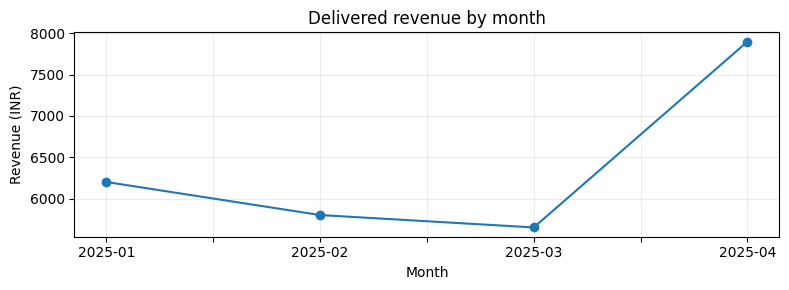

In [9]:
monthly = delivered.groupby(delivered["Order_Date"].dt.to_period("M"))["Revenue"].sum().sort_index()
display(monthly.to_frame("Delivered revenue (INR)"))
display(monthly.pct_change().mul(100).round(2).to_frame("Month-on-month change (%)"))
monthly.index = monthly.index.astype(str)
monthly.plot(kind="line", marker="o", figsize=(8, 3), title="Delivered revenue by month")
plt.ylabel("Revenue (INR)")
plt.xlabel("Month")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 3.4 Correlation and trend insights

A relationship between two variables does not establish causation. A negative correlation between delivery days and ratings could suggest an investigation, but it does not prove that slow delivery caused low ratings.

**Try this prompt**

```text
Calculate the Pearson correlation between Delivery_Days and Rating for
delivered orders with both values available. State the number of paired
observations. Explain the direction of the relationship and its limitations.
Do not claim causation.
```

Paired observations: 19
Pearson r: -0.968


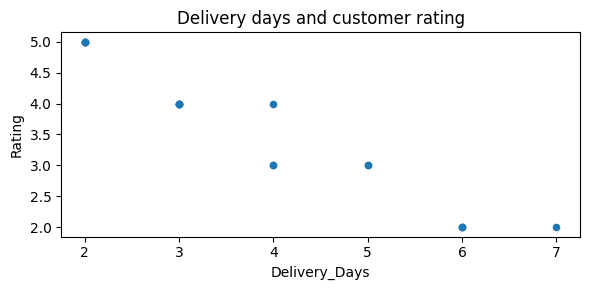

In [10]:
paired = delivered[["Delivery_Days", "Rating"]].dropna()
print("Paired observations:", len(paired))
print("Pearson r:", round(paired["Delivery_Days"].corr(paired["Rating"]), 3))
paired.plot(kind="scatter", x="Delivery_Days", y="Rating", figsize=(6, 3), title="Delivery days and customer rating")
plt.tight_layout()
plt.show()

### 3.5 Customer segmentation and clustering

Segmentation groups customers with similar characteristics. Clustering is an unsupervised ML technique that discovers groups from features such as spending and order frequency. GenAI can suggest features or generate clustering code, but an LLM response alone is not a fitted clustering model.

Start with a customer-level summary and simple business-defined segments. This is **rule-based segmentation, not clustering**. A clustering model would require appropriate feature scaling, a suitable sample and validation of the chosen groups.

In [11]:
customers = delivered.groupby("Customer_ID").agg(
    Order_Count=("Order_ID", "count"), Total_Spend=("Revenue", "sum")
).reset_index()
customers["Segment"] = "One-time shopper"
customers.loc[customers["Order_Count"] >= 2, "Segment"] = "Repeat shopper"
customers.sort_values("Total_Spend", ascending=False)

,Customer_ID,Order_Count,Total_Spend,Segment
3,C05,3,5300.0,Repeat shopper
2,C03,3,4100.0,Repeat shopper
6,C08,2,3700.0,Repeat shopper
1,C02,3,2900.0,Repeat shopper
7,C09,2,2600.0,Repeat shopper
5,C07,2,2350.0,Repeat shopper
0,C01,2,2300.0,Repeat shopper
8,C11,1,1500.0,One-time shopper
4,C06,1,800.0,One-time shopper


**Try this prompt**

```text
Using the customer summary, compare one-time and repeat shoppers by
count and spending. Suggest what extra data would help build meaningful
customer clusters. Explain the difference between a business rule and
K-means clustering. Do not invent a trained model or claim optimal clusters.
```

---

## 4. Automated report generation

### 4.1 Turn verified numbers into a management report

An analytical report should contain a clear scope, findings supported by calculations, limitations, and suggested actions. AI can convert technical results into accessible language for different stakeholders.

| Audience | What to emphasize |
|---|---|
| Executive | Key KPIs, risks and decisions |
| Sales manager | Category and regional performance |
| Operations manager | Delivery times, cancellations and data issues |
| Analyst | Definitions, methods, assumptions and reproducibility |

Copy the verified results from Section 3 or upload the file and explicitly request execution.

In [12]:
# Prepare the figures for a report.
report_facts = {
    "Scope": "Validated fictional retail orders only",
    "Raw rows": len(df),
    "Duplicates removed": int(df.duplicated().sum()),
    "Orders needing review": len(exceptions),
    "Delivered revenue (INR)": round(delivered["Revenue"].sum(), 2),
    "Delivered orders": len(delivered),
    "Cancellation rate (%)": round(100 * (ready["Status"] == "Cancelled").mean(), 2),
    "Top category": category_revenue.index[0],
    "Top category revenue (INR)": category_revenue.iloc[0],
}
for key, value in report_facts.items():
    print(f"{key}: {value}")

Scope: Validated fictional retail orders only
Raw rows: 28
Duplicates removed: 1
Orders needing review: 5
Delivered revenue (INR): 25550.0
Delivered orders: 19
Cancellation rate (%): 13.64
Top category: Electronics
Top category revenue (INR): 10200.0


**Try this prompt**

```text
You are preparing a management briefing using the verified figures below.
[Paste the printed figures here.]
Write a 150-word report with these headings: Scope, Key Findings,
Data Quality Limitations, and Recommended Next Steps. Use only the
supplied facts, distinguish observations from hypotheses, and avoid
claiming profit, growth causes or company-wide totals. Mark any
recommendation as a proposed action rather than a proven result.
```

### 4.2 Generate a presentation or PDF report

A report can become a document or slide deck using an AI assistant that supports file creation, or the draft can be pasted into Word, PowerPoint or another familiar tool.

**Check every chart, figure, label and conclusion before distributing it.**

**Try this prompt**

```text
Create a four-slide management briefing from the verified retail results:
1. Scope and data quality
2. Key performance indicators
3. Category and monthly performance (use verified tables)
4. Recommendations and questions for further investigation
Use INR labels, disclose excluded records, and do not add unsupported numbers.
If you cannot generate a presentation file, provide the slide content only.
```

### 4.3 Scheduled and updated reports

An AI-generated report is not automatically live. Recurring reports require a data connection, a schedule or refresh mechanism, appropriate access and validation. The generation tool can then draft a narrative from updated results.

Pipeline automation and dashboard refresh design are covered in Lecture 3.

### 4.4 Structuring unstructured business information

Extracting fields from written text is useful when an analyst receives notes, emails or transaction descriptions rather than a table.

**Raw text (example adapted from the lecture)**

Ramesh Gupta bought 8 kg of orange at a price of 80 rupees. Priya Singh bought 15 kg of watermelon at a price of 300 rupees. Anjali Mehta bought 3 kg of grapes at a price of 90 rupees. Vikram Rao bought 6 kg of papaya at a price of 60 rupees. Neha Kumari bought 2 kg of kiwi at a price of 120 rupees.

**Try this prompt**

```text
Extract the transactions into a table with Customer_Name, Product,
Quantity_kg, Price_Stated_INR, Date and Payment_Method. Use null when a
field is absent. Do not assume whether the stated price is per kg or the
transaction total. Explain that ambiguity before calculating revenue.
```

<details>
<summary><strong>Reveal suggested answer</strong></summary>

| Customer_Name | Product | Quantity_kg | Price_Stated_INR | Date | Payment_Method |
|---|---|---:|---:|---|---|
| Ramesh Gupta | Orange | 8 | 80 | null | null |
| Priya Singh | Watermelon | 15 | 300 | null | null |
| Anjali Mehta | Grapes | 3 | 90 | null | null |
| Vikram Rao | Papaya | 6 | 60 | null | null |
| Neha Kumari | Kiwi | 2 | 120 | null | null |

The text does not unambiguously identify unit prices or total prices. Do not calculate revenue without clarification.

</details>

---

## 5. Hands-on practice: food delivery orders

The lecture includes a Zomato dummy dataset activity. Use this self-contained fictional food-delivery dataset, or the original linked practice sheet in the references. The example is not actual Zomato transaction data.

Run the following cell, then upload `food_delivery_orders.csv` to your AI assistant.

In [13]:
food_csv = 'Order_ID,Order_Date,Customer_Name,Payment_Method,Order_Amount\nZ001,2025-05-01,Asha,cash,250\nZ002,2025-05-02,,Cash,400\nZ003,2025-05-02,Ravi,Credit Card,"₹1,250"\nZ004,2025-05-03,Meera,credit card,550\nZ005,2025-05-04,Imran,UPI,-90\nZ006,2025-05-05,Neha,upi,unknown\nZ007,2025-05-05,Isha,Cash,300\nZ008,2099-01-01,Arun,UPI,650\nZ009,2025-05-06,Sana,Credit Card,450\nZ010,2025-05-07,Karan,Cash,\nZ003,2025-05-02,Ravi,Credit Card,"₹1,250"\nZ011,2025-05-08,N/A,UPI,120\n'
with open("food_delivery_orders.csv", "w", encoding="utf-8") as f:
    f.write(food_csv)
food = pd.read_csv("food_delivery_orders.csv")
food

,Order_ID,Order_Date,Customer_Name,Payment_Method,Order_Amount
0,Z001,2025-05-01,Asha,cash,250
1,Z002,2025-05-02,NaN,Cash,400
2,Z003,2025-05-02,Ravi,Credit Card,"₹1,250"
3,Z004,2025-05-03,Meera,credit card,550
4,Z005,2025-05-04,Imran,UPI,-90
5,Z006,2025-05-05,Neha,upi,unknown
6,Z007,2025-05-05,Isha,Cash,300
7,Z008,2099-01-01,Arun,UPI,650
8,Z009,2025-05-06,Sana,Credit Card,450
9,Z010,2025-05-07,Karan,Cash,NaN


### Your assignment

Act as a junior analyst responsible for preparing a food-delivery performance report. Use AI to help, but verify each output independently.

| Task | What to deliver |
|---|---|
| 1. Missing values | IDs with missing Customer_Name |
| 2. Payment labels | Standardized Cash, Credit Card and UPI labels |
| 3. Amount inconsistencies | Numeric conversion, invalid values and missing amounts |
| 4. Duplicate IDs | List repeated IDs; remove only exact duplicates |
| 5. Date validation | Orders dated after 2025-05-31 (the exercise reporting cutoff) |
| 6. Descriptive statistics | Mean, median, minimum and maximum of valid order amounts |
| 7. Payment frequency | Most frequently used payment method among valid orders |
| 8. Business report | Three verified observations and one suggested action |

For this exercise, orders have positive amounts. Negative amounts require review because there is no refund indicator. Missing names may be marked Unknown; missing amounts and invalid dates must not be invented.

**Try this prompt**

```text
Inspect this fictional food-delivery dataset and complete the eight tasks
listed above. First report issues and proposed rules, then apply the
approved rules. Retain a review table of excluded records. Use a fixed
reporting cutoff of 2025-05-31. Show executable Pandas code, row counts,
statistics and the payment method frequencies for valid orders only.
Do not invent missing names, prices or dates.
```

### Verify your results

Complete the exercise before running the following solution cells.

In [14]:
print("Missing customer names:")
display(food.loc[food["Customer_Name"].isna(), ["Order_ID", "Customer_Name"]])
print("Duplicate IDs:")
display(food.loc[food["Order_ID"].duplicated(keep=False)])

food_clean = food.drop_duplicates().copy()
food_clean["Customer_Name"] = food_clean["Customer_Name"].fillna("Unknown")
food_clean["Payment_Method"] = food_clean["Payment_Method"].str.strip().str.title()
food_clean["Order_Amount"] = pd.to_numeric(
    food_clean["Order_Amount"].astype(str).str.replace("₹", "", regex=False).str.replace(",", "", regex=False),
    errors="coerce"
)
food_clean["Order_Date"] = pd.to_datetime(food_clean["Order_Date"], errors="coerce")
cutoff = pd.Timestamp("2025-05-31")
invalid = (food_clean["Order_Amount"].isna() | (food_clean["Order_Amount"] <= 0)
           | food_clean["Order_Date"].isna() | (food_clean["Order_Date"] > cutoff)
           | food_clean["Order_ID"].duplicated(keep=False))
food_valid = food_clean[~invalid].copy()
print("Orders to review:")
display(food_clean.loc[invalid])
print("Valid orders:", len(food_valid))

Missing customer names:


,Order_ID,Customer_Name
1,Z002,NaN
11,Z011,NaN


Duplicate IDs:


,Order_ID,Order_Date,Customer_Name,Payment_Method,Order_Amount
2,Z003,2025-05-02,Ravi,Credit Card,"₹1,250"
10,Z003,2025-05-02,Ravi,Credit Card,"₹1,250"


Orders to review:


,Order_ID,Order_Date,Customer_Name,Payment_Method,Order_Amount
4,Z005,2025-05-04,Imran,Upi,-90.0
5,Z006,2025-05-05,Neha,Upi,NaN
7,Z008,2099-01-01,Arun,Upi,650.0
9,Z010,2025-05-07,Karan,Cash,NaN


Valid orders: 7


In [15]:
display(food_valid["Order_Amount"].agg(["mean", "median", "min", "max"]).round(2).to_frame("INR"))
display(food_valid["Payment_Method"].value_counts().to_frame("Valid orders"))

,INR
mean,474.29
median,400.00
min,120.00
max,1250.00


,Valid orders
Payment_Method,
Cash,3
Credit Card,3
Upi,1


**Discuss:** How would the results change if you kept the duplicate record or converted the missing amounts to zero? Which decision is justified by the business rules?

---

## 6. **Business domain use cases**

Generative AI can assist analysts in different industries. The table presents illustrative workflows, not measured claims about actual companies.

| Industry | Typical data | AI-assisted tasks | What to verify |
|---|---|---|---|
| Retail and e-commerce | Transactions, inventory, returns, ratings | Category insights, customer segments, sales summaries, descriptions | Revenue definitions, duplicates, refunds and stock data |
| Marketing and advertising | Campaign cost, clicks, conversions, audience | Campaign summaries, segment comparisons, copy drafts | CTR, conversion rate, attribution and denominator |
| Finance and banking | Transactions, budgets, risk metrics | Narrative reports, explanations of flagged activity | Calculations, access permissions and compliance |
| Healthcare | De-identified operational data, visit counts | Draft operational summaries, demand patterns | Privacy, data accuracy and clinical review where applicable |
| Human resources | Anonymized surveys, attrition, attendance | Feedback themes, workforce reporting | Privacy, bias, fairness and human review |
| Cross-industry reporting | Verified KPIs and dashboards | Executive briefings, plain-language narratives | Traceability to data and metric definitions |

Forecasting, fraud detection and clustering usually rely on statistical or ML models. GenAI can help build or explain those workflows, but is not a substitute for validated models.

### Retail case study: from question to decision

Use the retail file from Sections 2 and 3. Imagine a manager wants to improve customer satisfaction while reducing cancellations.

| Step | Question to ask |
|---|---|
| Initial understanding | What does the dataset contain, and what is missing? |
| Data preparation | Which records need review, and why? |
| Descriptive analysis | Which categories, regions and months produce the most delivered revenue? |
| Insight generation | How do delivery days relate to ratings? |
| Problem identification | Which regions show high cancellation counts or low ratings? |
| Visual evidence | Which existing tables or charts support the findings? |
| Actionable insights | What should we investigate or test next? |

Much of the work is already complete. Use the results rather than restarting the entire cleaning workflow.

In [16]:
region_operations = ready.groupby("Region").agg(
    Orders=("Order_ID", "count"),
    Cancelled=("Status", lambda s: (s == "Cancelled").sum()),
    Average_Rating=("Rating", "mean")
)
region_operations["Cancellation_Rate_%"] = 100 * region_operations["Cancelled"] / region_operations["Orders"]
region_operations.round(2)

,Orders,Cancelled,Average_Rating,Cancellation_Rate_%
Region,,,,
North,7,2,2.80,28.57
South,8,0,3.62,0.00
West,7,1,4.33,14.29


**Try this prompt**

```text
Use the verified regional operations table and previous results.
Identify one area that deserves investigation, explain the evidence,
propose two actions that could be tested, and list additional data needed.
Do not claim a cause of cancellations or poor ratings. Small groups should
be treated cautiously.
```

### Discussion: choose a business domain

Pick one industry from the table. Identify a business question, the necessary columns, a suitable AI-assisted task, one metric to verify and one risk.

**Example:** A marketing analyst might compare conversion rates across campaigns, but needs impressions or clicks, conversions, campaign identifiers and a consistent attribution period. GenAI can suggest an analysis and draft the summary, while calculations must be verified.

---

## 7. Limitations and best practices

| Risk | Example | Better practice |
|---|---|---|
| Hallucination | AI reports a revenue figure without calculating it | Request execution and reconcile results independently |
| Incorrect cleaning | AI drops all missing values including expected ones | Agree on rules before modifying data |
| Misleading statistics | AI averages averages or uses the wrong denominator | Define metrics and verify formulas |
| Correlation vs causation | AI says delayed delivery caused poor ratings | Treat relationships as evidence for further investigation |
| Privacy | Uploading identifiable customer or employee information | Use approved tools and anonymized or synthetic data |
| Reproducibility | AI changes methods without documenting them | Preserve raw data, prompts, code and cleaning logs |
| Unsupported reports | AI creates convincing slides with invented business figures | Review each figure and its source |

**Before sharing AI-assisted analysis:** check the input data, metric definitions, calculations, evidence, limitations and privacy requirements.

---

## 8. Recap and knowledge check

1. An assistant has not received your dataset. Can it calculate your actual revenue?
2. Why should a missing transaction price not automatically be filled with the median?
3. What is the difference between an exact duplicate and a conflicting order ID?
4. What does IQR identify? Does it prove a value is wrong?
5. Which denominator should be used for average delivered order value?
6. Does a negative delivery-time/rating correlation prove causation?
7. What is the difference between rule-based segmentation and clustering?
8. Can a generated report be considered live merely because AI wrote it?
9. What should a manager see in an AI-generated business report?

<details>
<summary><strong>Reveal suggested answer</strong></summary>

1. No, not without relevant data or authorized access to it.
2. It would invent a financial amount; flag it for review unless an appropriate policy exists.
3. Exact duplicates have identical contents; conflicting IDs have differing records needing investigation.
4. Potential outliers; they are not necessarily errors.
5. The number of delivered orders included in the calculation.
6. No.
7. Rules define groups manually; clustering finds groups using a fitted algorithm.
8. No, a live or scheduled refresh mechanism is required.
9. Verified metrics, scope, evidence, limitations and actionable next steps.

</details>

**Key takeaway:** Generative AI helps analysts move faster through data preparation, exploration and communication. It does not replace statistical understanding, business context or verification.

The next lesson covers AI-optimized ETL, data pipelines and tailored visualization.